# Неделя 17. PyTorch: тот же цикл обучения с autograd

**Tech Orda · Gizatov A. S. · beginner ML/AI · Python 3**

**Практика:** 27 минут guided comparison; подробный повтор — вне занятий. На неделе также 72 минуты разбора теории: всего
2 занятия × 90 минут = 4 академических часа. Домашнее задание выполняется отдельно.

**Результат:** обучить настоящую torch.nn сеть на локальных digits, проверить градиенты, сохранить validation checkpoint и выполнить детерминированный inference.

Ячейки идут от постановки задачи и описательной аналитики к алгоритму,
проверке и интерпретации. Сначала предскажите результат ячейки, затем запускайте.
Данные уже находятся в `../datasets`; интернет, GPU и API-ключи не нужны.
Запуск: **Restart Kernel → Run All**. Зависимости устанавливаются заранее
по инструкции в корне репозитория; из notebook ничего не устанавливается.


In [1]:
# Ограничиваем число потоков: небольшие учебные задачи запускаются на CPU.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
# Поддерживается запуск из корня репозитория, practice/ и homework/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "course_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте notebook внутри клонированного репозитория")
WEEK = ROOT / 'week_17_backprop_frameworks'
DATA = WEEK / "datasets"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                      "grid.alpha": 0.2, "font.size": 10})


## Локальные digits 8×8 и единая разбивка

Одна строка — 64 пикселя и цифра 0…9. Известный диапазон пикселя 0…16
позволяет делить на 16 без оценки статистик по данным. Сначала 20% test,
затем 25% оставшихся строк на validation: примерно **60/20/20**.
`sample_id` и target исключены из X. Все три лабораторные недели используют
одинаковые индексы; test не выбирает число эпох.


In [2]:
df = pd.read_csv(DATA / "digits_8x8.csv").set_index("sample_id")
assert df.index.is_unique and df.notna().all().all()
pixels = df.drop(columns="target")
assert pixels.shape[1] == 64 and pixels.min().min() >= 0 and pixels.max().max() <= 16
all_ids = df.index.to_numpy()
trainval_ids, test_ids = train_test_split(all_ids, test_size=0.2,
    stratify=df.target, random_state=SEED)
train_ids, val_ids = train_test_split(trainval_ids, test_size=0.25,
    stratify=df.loc[trainval_ids, "target"], random_state=SEED + 1)
assert set(train_ids).isdisjoint(val_ids) and set(trainval_ids).isdisjoint(test_ids)
def arrays(ids):
    return (pixels.loc[ids].to_numpy(dtype="float32") / 16.0,
            df.loc[ids, "target"].to_numpy(dtype="int64"))
X_train, y_train = arrays(train_ids)
X_val, y_val = arrays(val_ids)
X_test, y_test = arrays(test_ids)
print({"train": X_train.shape, "validation": X_val.shape, "sealed_test": X_test.shape})


{'train': (1077, 64), 'validation': (360, 64), 'sealed_test': (360, 64)}


## EDA только train: баланс, распределение и изображения

Изображения уже уменьшены до 8×8, поэтому детали потеряны. Нулевые края
встречаются часто. В исходном экспорте нет ID автора почерка: random split
не проверяет перенос на полностью новых авторов. Сравнение framework на одном
seed — учебная иллюстрация, не рейтинг библиотек.


0    107
1    109
2    106
3    109
4    109
5    109
6    109
7    107
8    104
9    108
Name: train_count, dtype: int64

,mean,std,min,max
0,0.000,0.000,0.0,0.000
1,0.019,0.059,0.0,0.500
2,0.323,0.295,0.0,1.000
3,0.738,0.267,0.0,1.000
4,0.745,0.265,0.0,1.000
5,0.374,0.358,0.0,1.000
6,0.089,0.214,0.0,1.000
7,0.009,0.069,0.0,0.938
8,0.000,0.005,0.0,0.125
9,0.128,0.203,0.0,0.938


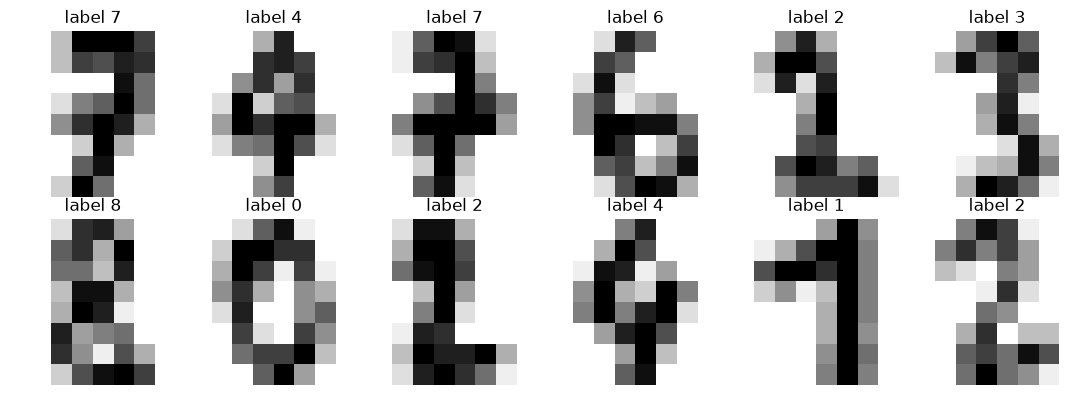

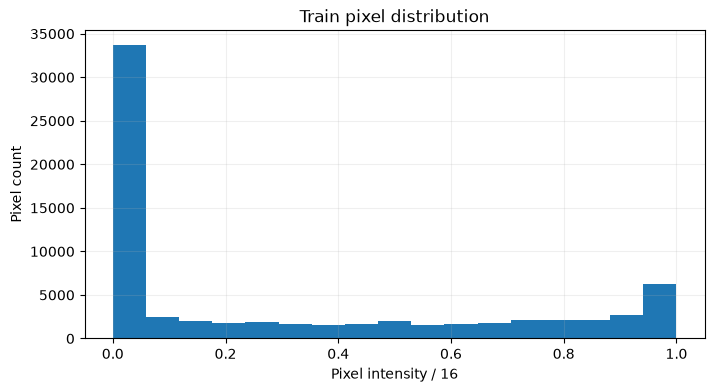

In [3]:
display(pd.Series(y_train).value_counts().sort_index().rename("train_count"))
display(pd.DataFrame(X_train).describe().T[["mean", "std", "min", "max"]].head(12).round(3))
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, image, label in zip(axes.ravel(), X_train[:12], y_train[:12]):
    ax.imshow(image.reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"label {label}"); ax.axis("off")
plt.tight_layout(); plt.show()
plt.hist(X_train.ravel(), bins=17)
plt.xlabel("Pixel intensity / 16"); plt.ylabel("Pixel count"); plt.title("Train pixel distribution")
plt.show()


## 1. Tensor, module, loss, optimizer

Тензор хранит данные; `nn.Module` хранит слои и параметры; autograd вычисляет
производные; optimizer обновляет веса. Работаем строго на CPU.
`CrossEntropyLoss` получает **logits**, поэтому softmax перед loss не добавляем.
Целевые классы — целые числа dtype `long`.


In [4]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
device = torch.device("cpu")
Xtr = torch.tensor(X_train, dtype=torch.float32, device=device)
ytr = torch.tensor(y_train, dtype=torch.long, device=device)
Xva = torch.tensor(X_val, dtype=torch.float32, device=device)
yva = torch.tensor(y_val, dtype=torch.long, device=device)
model = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.1), nn.Linear(32, 10)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True,
    num_workers=0, generator=torch.Generator().manual_seed(SEED))
print("PyTorch", torch.__version__, "parameters:", sum(p.numel() for p in model.parameters()))
print(model)


PyTorch 2.14.1+cpu parameters: 2410
Sequential(
  (0): Linear(in_features=64, out_features=32, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.1, inplace=False)
  (3): Linear(in_features=32, out_features=10, bias=True)
)


## 2. Один backward pass

`loss.backward()` вычисляет $\partial L/\partial\theta$ и накапливает его в
`.grad`. Поэтому перед новым шагом вызываем `zero_grad`.
Здесь только инспектируем градиенты: `optimizer.step()` пока не выполняется.


In [5]:
model.train()
optimizer.zero_grad(set_to_none=True)
logits = model(Xtr[:64])
loss = loss_fn(logits, ytr[:64])
loss.backward()
gradient_rows = []
for name, parameter in model.named_parameters():
    assert parameter.grad is not None and torch.isfinite(parameter.grad).all()
    gradient_rows.append({"parameter": name, "shape": str(tuple(parameter.shape)),
                          "gradient_norm": parameter.grad.norm().item()})
display(pd.DataFrame(gradient_rows))
assert logits.shape == (64, 10)
optimizer.zero_grad(set_to_none=True)


,parameter,shape,gradient_norm
0,0.weight,"(32, 64)",0.248046
1,0.bias,"(32,)",0.057383
2,3.weight,"(10, 32)",0.158942
3,3.bias,"(10,)",0.137490


## 3. Train и eval — разные режимы

`model.train()` включает Dropout, `model.eval()` выключает его.
`torch.no_grad()` отключает построение графа градиентов при оценке.
Эти механизмы дополняют друг друга. Обучаем 24 эпохи, checkpoint выбираем
по validation loss, а не по последней эпохе и не по test accuracy.


In [6]:
history, best_loss, best_state, best_epoch = [], float("inf"), None, None
for epoch in range(1, 25):
    model.train(); loss_sum = 0.0
    for xb, yb in loader:
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        batch_loss = loss_fn(logits, yb)
        batch_loss.backward()
        optimizer.step()
        loss_sum += batch_loss.item()*len(xb)
    model.eval()
    with torch.no_grad():
        validation_logits = model(Xva)
        validation_loss = loss_fn(validation_logits, yva).item()
        validation_accuracy = (validation_logits.argmax(dim=1)==yva).float().mean().item()
    history.append({"epoch": epoch, "train_loss": loss_sum/len(Xtr),
                    "validation_loss": validation_loss, "validation_accuracy": validation_accuracy})
    if validation_loss < best_loss:
        best_loss, best_epoch = validation_loss, epoch
        best_state = {key: value.detach().clone() for key, value in model.state_dict().items()}
model.load_state_dict(best_state)
history = pd.DataFrame(history)
assert np.isfinite(history.select_dtypes("number")).all().all()
assert history.train_loss.iloc[-1] < history.train_loss.iloc[0]
print("Restored validation checkpoint epoch:", best_epoch)


Restored validation checkpoint epoch: 24


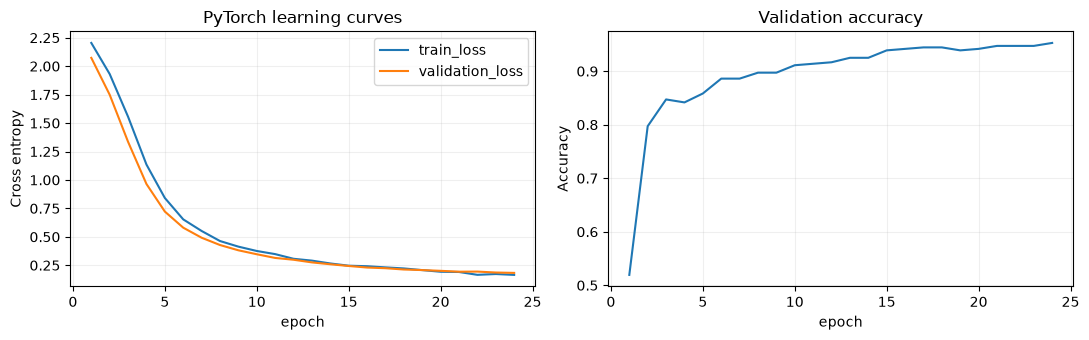

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
history.plot(x="epoch", y=["train_loss", "validation_loss"], ax=axes[0])
axes[0].set(ylabel="Cross entropy", title="PyTorch learning curves")
history.plot(x="epoch", y="validation_accuracy", ax=axes[1], legend=False)
axes[1].set(ylabel="Accuracy", title="Validation accuracy")
plt.tight_layout(); plt.show()


## 4. Финальный inference

Восстановленные веса заморожены для отчёта. Softmax теперь нужен для просмотра
вероятностей, а не для обучения. Высокая softmax-вероятность сама по себе
не доказывает хорошую калибровку на новом распределении.


Baseline test accuracy: 0.1
PyTorch test accuracy: 0.95
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.83      0.83      0.83        36
           2       0.97      1.00      0.99        35
           3       1.00      0.95      0.97        37
           4       0.92      1.00      0.96        36
           5       0.97      0.97      0.97        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.91      0.83      0.87        35
           9       0.90      0.97      0.93        36

    accuracy                           0.95       360
   macro avg       0.95      0.95      0.95       360
weighted avg       0.95      0.95      0.95       360



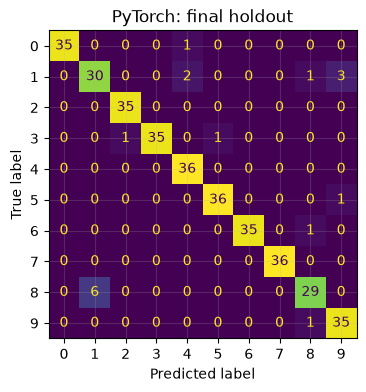

In [8]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
model.eval()
Xte = torch.tensor(X_test, dtype=torch.float32, device=device)
with torch.no_grad():
    test_logits = model(Xte)
    probability = torch.softmax(test_logits, dim=1).cpu().numpy()
    repeated_logits = model(Xte)
assert torch.equal(test_logits, repeated_logits), "Eval inference должен быть детерминированным"
assert np.allclose(probability.sum(axis=1), 1, atol=1e-6)
prediction = probability.argmax(axis=1)
print("Baseline test accuracy:", np.mean(y_test == np.bincount(y_train).argmax()))
print("PyTorch test accuracy:", accuracy_score(y_test, prediction))
print(classification_report(y_test, prediction, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, colorbar=False)
plt.title("PyTorch: final holdout"); plt.show()


## 5. Анализ ошибок без перенастройки

Посмотрим до шести ошибочных предсказаний. Если ошибок меньше, показываем
только имеющиеся. Это материал для следующей гипотезы, а не повод продолжить
выбор checkpoint по test.


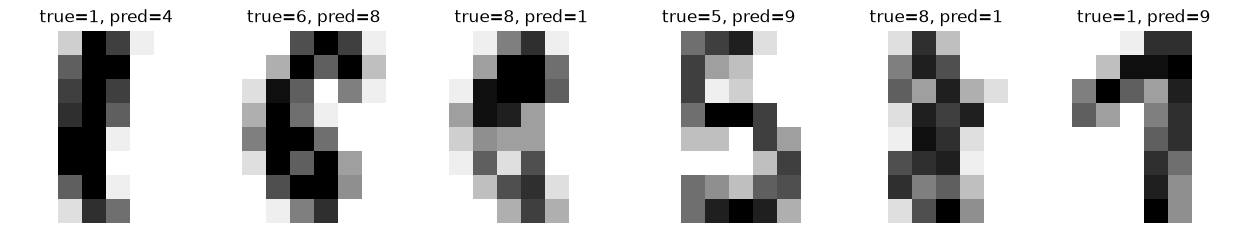

In [9]:
errors = np.flatnonzero(prediction != y_test)[:6]
if len(errors):
    fig, axes = plt.subplots(1, len(errors), figsize=(2.1*len(errors), 2.5), squeeze=False)
    for ax, index in zip(axes.ravel(), errors):
        ax.imshow(X_test[index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(f"true={y_test[index]}, pred={prediction[index]}"); ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("На этом holdout ошибок нет; это не гарантия качества на новых авторах почерка.")


## Сопоставление с NumPy

`forward` заменён слоями; ручной chain rule — autograd; обновление массивов —
Adam. В этой сети ReLU и Dropout, в NumPy lab — tanh и full-batch SGD, поэтому
значения метрик не должны совпадать. Чтобы сравнить реализации численно,
нужно одинаково задать архитектуру, веса, batch order, optimizer и dtype.

Источники: [PyTorch optimization tutorial](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html),
[autograd basics](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html),
[reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html).
